# Entrega 5 – Visión Artificial (ITM)
## Destilación de Conocimiento (KD por logits): de MobileNetV2 a una CNN liviana
### Defectos superficiales en acero laminado (NEU) – despliegue en edge

En la Entrega 4 se construyó un sistema robusto: **MobileNetV2 congelada + AutoGluon**. Ahora el reto es **comprimir ese conocimiento** en una CNN pequeña (*Alumno*) que pueda correr en un equipo embebido junto a la línea de producción.

**Plan del notebook**
1. Profesor: MobileNetV2 (Transfer Learning) con cabeza `Dense` que entrega **logits**.
2. Alumno: CNN compacta en escala de grises 128×128.
3. Destilación por logits con la pérdida combinada `α·CE(y, alumno) + (1-α)·T²·KL(p_prof^T ‖ p_alum^T)`.
4. Línea base: el mismo alumno **sin** destilación (para medir el aporte real de la KD).
5. Comparativa TL vs KD: Accuracy/F1, parámetros, MB, latencia, FPS y trade-off.
6. Exportación a TensorFlow Lite y estudio de hardware/cámara.

> Requiere haber ejecutado la Entrega 4 (usa `splits.csv`, `clases.json` y `salidas_E4/metricas_E4.json` para que la comparación sea con **las mismas imágenes de prueba**).

In [1]:
# ==== 1. Librerías y configuración ====
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

SALIDAS = "salidas_E5"; os.makedirs(SALIDAS, exist_ok=True)
IMG_PROF = (224, 224)   # entrada del Profesor (MobileNetV2, 3 canales)
IMG_ALUM = (128, 128)   # entrada del Alumno (1 canal, gris)
BATCH_SIZE = 32

splits = pd.read_csv("splits.csv")
CLASES = json.load(open("clases.json"))
NUM_CLASES = len(CLASES)
tr, va, te = [splits[splits.split == s] for s in ("train", "val", "test")]
print("Clases:", CLASES)
print("train/val/test:", len(tr), len(va), len(te))

Clases: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
train/val/test: 1260 270 270


## 2. Datos
Cada imagen se carga **una sola vez** en dos versiones: 224×224×3 normalizada para el Profesor y 128×128×1 en [0,1] para el Alumno. Las imágenes del NEU son en gris, por eso el Alumno usa un solo canal (3× menos cómputo en la primera capa).

In [2]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def cargar(ruta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=1, expand_animations=False)
    img = tf.cast(img, tf.float32)
    x_prof = preprocess_input(tf.image.grayscale_to_rgb(tf.image.resize(img, IMG_PROF)))   # [-1,1]
    x_alum = tf.image.resize(img, IMG_ALUM) / 255.0                                         # [0,1]
    return x_prof, x_alum

def cargar_split(df):
    xp, xa = zip(*[cargar(r) for r in df.ruta])
    return np.stack(xp), np.stack(xa), df.label.values.astype(np.int32)

t0 = time.time()
Xp_tr, Xa_tr, y_tr = cargar_split(tr)
Xp_va, Xa_va, y_va = cargar_split(va)
Xp_te, Xa_te, y_te = cargar_split(te)
print(f"Cargado en {time.time()-t0:.1f} s | Profesor: {Xp_tr.shape} | Alumno: {Xa_tr.shape}")

Cargado en 14.0 s | Profesor: (1260, 224, 224, 3) | Alumno: (1260, 128, 128, 1)


## 3. Modelo Profesor (Transfer Learning)

Para destilar **por logits** se necesita una red que entregue logits y sea diferenciable. La cabeza de AutoGluon de la Entrega 4 es un ensamble tabular (árboles, boosting) que solo entrega probabilidades, por eso el Profesor es la **misma MobileNetV2 congelada** con una capa `Dense` lineal (sin softmax), tal como en la plantilla del docente. Su desempeño es equivalente al sistema de la Entrega 4 (se comprueba abajo).

In [3]:
def construir_profesor(input_shape=(224, 224, 3), num_clases=6):
    base = keras.applications.MobileNetV2(input_shape=input_shape, include_top=False,
                                          weights="imagenet", pooling="avg")
    base.trainable = False                     # backbone congelado
    inputs = keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.Dropout(0.2)(x)
    logits = layers.Dense(num_clases, name="logits_profesor")(x)   # SIN softmax
    return keras.Model(inputs, logits, name="Profesor_TL")

profesor = construir_profesor(IMG_PROF + (3,), NUM_CLASES)
profesor.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                 metrics=["accuracy"])
hist_prof = profesor.fit(Xp_tr, y_tr, validation_data=(Xp_va, y_va), epochs=12, batch_size=BATCH_SIZE,
                         callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4,
                                                                  restore_best_weights=True)], verbose=2)
profesor.trainable = False   # El profesor NUNCA se entrena durante la destilación

Epoch 1/12
40/40 - 34s - 855ms/step - accuracy: 0.7222 - loss: 0.8445 - val_accuracy: 0.9852 - val_loss: 0.2092
Epoch 2/12
40/40 - 25s - 636ms/step - accuracy: 0.9778 - loss: 0.1579 - val_accuracy: 0.9889 - val_loss: 0.0916
Epoch 3/12
40/40 - 25s - 616ms/step - accuracy: 0.9913 - loss: 0.0888 - val_accuracy: 0.9889 - val_loss: 0.0652
Epoch 4/12
40/40 - 42s - 1s/step - accuracy: 0.9960 - loss: 0.0588 - val_accuracy: 0.9889 - val_loss: 0.0515
Epoch 5/12
40/40 - 25s - 630ms/step - accuracy: 0.9960 - loss: 0.0443 - val_accuracy: 0.9889 - val_loss: 0.0424
Epoch 6/12
40/40 - 40s - 994ms/step - accuracy: 0.9968 - loss: 0.0369 - val_accuracy: 0.9889 - val_loss: 0.0356


In [4]:
logits_te_prof = profesor.predict(Xp_te, verbose=0)
pred_prof = logits_te_prof.argmax(1)
print(f"Profesor -> Accuracy prueba: {accuracy_score(y_te, pred_prof):.4f} | "
      f"F1 macro: {f1_score(y_te, pred_prof, average='macro'):.4f}")

Profesor -> Accuracy prueba: 0.9815 | F1 macro: 0.9815


### Logits del Profesor (precalculados)
Como el Profesor está congelado y no se usa aumento de datos, sus logits para cada imagen de entrenamiento **son siempre los mismos**. Se calculan una sola vez (en vez de en cada paso de entrenamiento como en la plantilla): el resultado matemático es idéntico y el entrenamiento del Alumno es ~10× más rápido en un portátil sin GPU.

In [5]:
logits_tr_prof = profesor.predict(Xp_tr, verbose=0).astype(np.float32)
T_demo = 4.0
p_dura = tf.nn.softmax(logits_tr_prof[:1]).numpy().round(3)
p_suave = tf.nn.softmax(logits_tr_prof[:1] / T_demo).numpy().round(3)
print("Clase real:", CLASES[y_tr[0]])
print("Softmax normal (T=1):", dict(zip(CLASES, p_dura[0])))
print("Softmax suave (T=4): ", dict(zip(CLASES, p_suave[0])))
print("-> con T=4 se ven las 'relaciones entre clases' (dark knowledge) que aprende el alumno")

Clase real: scratches
Softmax normal (T=1): {'crazing': np.float32(0.0), 'inclusion': np.float32(0.005), 'patches': np.float32(0.001), 'pitted_surface': np.float32(0.0), 'rolled-in_scale': np.float32(0.0), 'scratches': np.float32(0.993)}
Softmax suave (T=4):  {'crazing': np.float32(0.039), 'inclusion': np.float32(0.159), 'patches': np.float32(0.109), 'pitted_surface': np.float32(0.059), 'rolled-in_scale': np.float32(0.052), 'scratches': np.float32(0.582)}
-> con T=4 se ven las 'relaciones entre clases' (dark knowledge) que aprende el alumno


## 4. Modelo Alumno (CNN liviana)
Tres bloques `Conv → BatchNorm → ReLU → MaxPool` y **Global Average Pooling** en lugar de `Flatten` (con `Flatten` la capa densa tendría cientos de miles de pesos; con GAP casi ninguno). Entrada de 1 canal a 128×128.

In [6]:
def crear_alumno(input_shape=(128, 128, 1), num_clases=6):
    inputs = keras.Input(shape=input_shape)
    x = inputs
    for filtros in (16, 32, 64):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x)   # momentum 0.9: estadísticas estables con pocos lotes
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(96, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    logits = layers.Dense(num_clases, name="logits_alumno")(x)   # Retorna LOGITS
    return keras.Model(inputs, logits, name="Alumno_Liviano")

alumno = crear_alumno(IMG_ALUM + (1,), NUM_CLASES)
print(f"Parámetros Profesor: {profesor.count_params():,}")
print(f"Parámetros Alumno:   {alumno.count_params():,}  "
      f"({profesor.count_params() / alumno.count_params():.0f}x más pequeño)")
alumno.summary()

Parámetros Profesor: 2,265,670
Parámetros Alumno:   79,606  (28x más pequeño)


Model: "Alumno_Liviano"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 128, 128, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 16)        │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 16)        │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 32)          │           4,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_1 (ReLU)                       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_2 (ReLU)                       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 96)          │          55,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 96)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 96)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ logits_alumno (Dense)                │ (None, 6)                   │             582 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,606 (310.96 KB)

 Trainable params: 79,382 (310.09 KB)

 Non-trainable params: 224 (896.00 B)

## 5. Destilación por logits

Pérdida combinada (plantilla del docente):

$$\mathcal{L} = \alpha \cdot CE(y,\ z_{alum}) + (1-\alpha)\cdot T^2 \cdot KL\big(\text{softmax}(z_{prof}/T)\ \|\ \text{softmax}(z_{alum}/T)\big)$$

- `α = 0.3`: 30 % etiqueta real, 70 % imitar al Profesor.
- `T = 4`: suaviza las probabilidades para transmitir qué clases se parecen entre sí.
- `T²` compensa que los gradientes de la parte suave se hacen `1/T²` más pequeños.

La función `crear_paso` es la misma `paso_destilacion` de la plantilla, envuelta para poder entrenar dos alumnos (con y sin KD) con optimizadores independientes. Con `α = 1` la parte de KD pesa cero → entrenamiento normal (línea base).

In [7]:
loss_hard_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
loss_kd_fn = keras.losses.KLDivergence()

def crear_paso(modelo, optimizador):
    @tf.function
    def paso_destilacion(x_batch, y_batch, logits_prof, alpha, temperatura):
        with tf.GradientTape() as tape:
            logits_alum = modelo(x_batch, training=True)
            # Pérdida frente a la etiqueta real
            loss_real = loss_hard_fn(y_batch, logits_alum)
            # Probabilidades suavizadas por temperatura
            prob_prof_suave = tf.nn.softmax(logits_prof / temperatura, axis=-1)
            prob_alum_suave = tf.nn.softmax(logits_alum / temperatura, axis=-1)
            # Divergencia KL escalada por T^2
            loss_kd = loss_kd_fn(prob_prof_suave, prob_alum_suave) * (temperatura ** 2)
            # Combinación ponderada
            loss_total = alpha * loss_real + (1.0 - alpha) * loss_kd
        gradientes = tape.gradient(loss_total, modelo.trainable_variables)
        optimizador.apply_gradients(zip(gradientes, modelo.trainable_variables))
        pred = tf.argmax(logits_alum, axis=-1, output_type=y_batch.dtype)
        acc_batch = tf.reduce_mean(tf.cast(pred == y_batch, tf.float32))
        return loss_total, loss_real, loss_kd, acc_batch
    return paso_destilacion

def entrenar_alumno(modelo, alpha, temperatura, epochs=40, lr=2e-3, nombre="alumno", idx=None):
    # idx: subconjunto opcional de imágenes de entrenamiento (para el experimento con pocos datos)
    idx = np.arange(len(y_tr)) if idx is None else idx
    optimizador = keras.optimizers.Adam(learning_rate=lr)
    paso = crear_paso(modelo, optimizador)
    ds = (tf.data.Dataset.from_tensor_slices((Xa_tr[idx], y_tr[idx], logits_tr_prof[idx]))
          .shuffle(len(idx), seed=SEED).batch(BATCH_SIZE))
    historial, mejor_acc, mejores_pesos = [], -1, None
    for epoch in range(1, epochs + 1):
        if epoch == int(epochs * 0.7):                     # baja la tasa de aprendizaje al final
            optimizador.learning_rate.assign(lr / 5)
        m = []
        for x_b, y_b, lp_b in ds:
            # Aumento de datos simple: volteos (un defecto volteado sigue siendo el mismo defecto)
            x_b = tf.image.random_flip_left_right(tf.image.random_flip_up_down(x_b))
            m.append([v.numpy() for v in paso(x_b, y_b, lp_b, alpha, temperatura)])
        m = np.mean(m, axis=0)
        val_acc = accuracy_score(y_va, modelo(Xa_va, training=False).numpy().argmax(1))
        historial.append(dict(epoch=epoch, loss=m[0], loss_real=m[1], loss_kd=m[2], acc=m[3], val_acc=val_acc))
        if val_acc > mejor_acc:
            mejor_acc, mejores_pesos = val_acc, modelo.get_weights()
        if epoch % 5 == 0 or epoch == 1:
            print(f"[{nombre}] Época {epoch:02d}/{epochs} | Loss: {m[0]:.4f} (Real: {m[1]:.4f} | KD: {m[2]:.4f}) "
                  f"| Acc: {m[3]*100:.1f}% | Val acc: {val_acc*100:.1f}%")
    modelo.set_weights(mejores_pesos)       # se queda con la mejor época según validación
    print(f"[{nombre}] Mejor val acc: {mejor_acc*100:.1f}%")
    return pd.DataFrame(historial)

In [8]:
ALPHA = 0.3          # Peso de la etiqueta real (0.3 -> 30% real, 70% profesor)
TEMPERATURA = 4.0    # Qué tanto se suavizan las probabilidades entre clases
EPOCHS = 40

t0 = time.time()
hist_kd = entrenar_alumno(alumno, ALPHA, TEMPERATURA, EPOCHS, nombre="Alumno KD")
t_kd = time.time() - t0
print(f"\nDestilación completada en {t_kd/60:.1f} min.")

[Alumno KD] Época 01/40 | Loss: 2.2503 (Real: 1.1092 | KD: 2.7393) | Acc: 58.5% | Val acc: 23.0%
[Alumno KD] Época 05/40 | Loss: 1.0273 (Real: 0.4486 | KD: 1.2754) | Acc: 85.0% | Val acc: 84.1%
[Alumno KD] Época 10/40 | Loss: 0.8049 (Real: 0.3007 | KD: 1.0210) | Acc: 91.2% | Val acc: 84.1%
[Alumno KD] Época 15/40 | Loss: 0.7056 (Real: 0.2771 | KD: 0.8893) | Acc: 92.9% | Val acc: 88.5%
[Alumno KD] Época 20/40 | Loss: 0.6768 (Real: 0.2532 | KD: 0.8584) | Acc: 93.7% | Val acc: 90.0%
[Alumno KD] Época 25/40 | Loss: 0.6126 (Real: 0.2154 | KD: 0.7829) | Acc: 94.2% | Val acc: 77.0%
[Alumno KD] Época 30/40 | Loss: 0.5170 (Real: 0.1784 | KD: 0.6621) | Acc: 96.0% | Val acc: 97.4%
[Alumno KD] Época 35/40 | Loss: 0.4749 (Real: 0.1438 | KD: 0.6169) | Acc: 98.1% | Val acc: 96.7%
[Alumno KD] Época 40/40 | Loss: 0.4863 (Real: 0.1516 | KD: 0.6298) | Acc: 98.0% | Val acc: 98.5%
[Alumno KD] Mejor val acc: 98.5%

Destilación completada en 7.0 min.


### Línea base: mismo Alumno entrenado sin Profesor (α = 1)

In [9]:
keras.utils.set_random_seed(SEED)
alumno_base = crear_alumno(IMG_ALUM + (1,), NUM_CLASES)
hist_base = entrenar_alumno(alumno_base, alpha=1.0, temperatura=TEMPERATURA, epochs=EPOCHS, nombre="Sin KD")

[Sin KD] Época 01/40 | Loss: 0.8868 (Real: 0.8868 | KD: 3.1911) | Acc: 66.0% | Val acc: 23.0%
[Sin KD] Época 05/40 | Loss: 0.4068 (Real: 0.4068 | KD: 7.0311) | Acc: 86.3% | Val acc: 88.1%
[Sin KD] Época 10/40 | Loss: 0.2083 (Real: 0.2083 | KD: 11.6089) | Acc: 92.7% | Val acc: 91.9%
[Sin KD] Época 15/40 | Loss: 0.1715 (Real: 0.1715 | KD: 14.6759) | Acc: 94.2% | Val acc: 84.1%
[Sin KD] Época 20/40 | Loss: 0.1997 (Real: 0.1997 | KD: 20.2430) | Acc: 94.0% | Val acc: 85.6%
[Sin KD] Época 25/40 | Loss: 0.1573 (Real: 0.1573 | KD: 22.6260) | Acc: 94.9% | Val acc: 64.1%
[Sin KD] Época 30/40 | Loss: 0.0662 (Real: 0.0662 | KD: 24.9270) | Acc: 97.5% | Val acc: 96.3%
[Sin KD] Época 35/40 | Loss: 0.0487 (Real: 0.0487 | KD: 28.8896) | Acc: 98.4% | Val acc: 88.1%
[Sin KD] Época 40/40 | Loss: 0.0617 (Real: 0.0617 | KD: 29.0112) | Acc: 98.1% | Val acc: 97.4%
[Sin KD] Mejor val acc: 98.9%


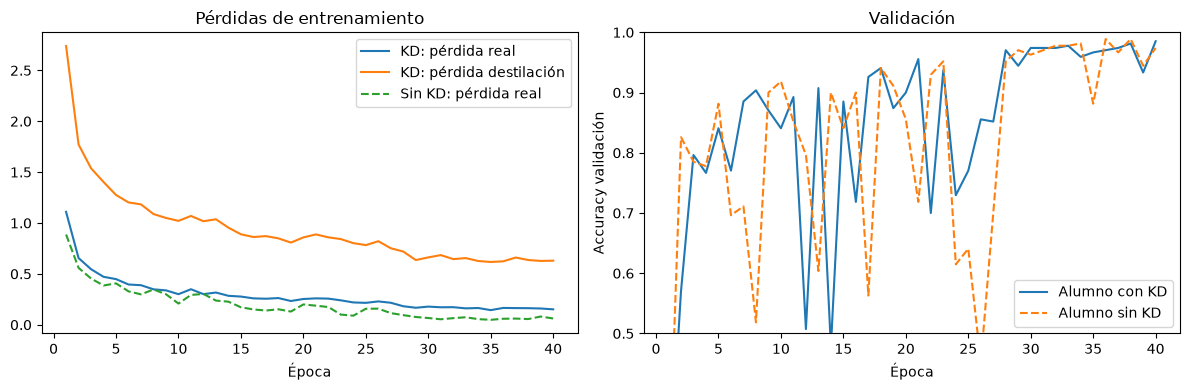

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_kd.epoch, hist_kd.loss_real, label="KD: pérdida real")
ax[0].plot(hist_kd.epoch, hist_kd.loss_kd, label="KD: pérdida destilación")
ax[0].plot(hist_base.epoch, hist_base.loss_real, "--", label="Sin KD: pérdida real")
ax[0].set_xlabel("Época"); ax[0].set_title("Pérdidas de entrenamiento"); ax[0].legend()
ax[1].plot(hist_kd.epoch, hist_kd.val_acc, label="Alumno con KD")
ax[1].plot(hist_base.epoch, hist_base.val_acc, "--", label="Alumno sin KD")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Accuracy validación"); ax[1].set_title("Validación"); ax[1].legend()
ax[1].set_ylim(0.5, 1.0)
plt.tight_layout(); plt.savefig(f"{SALIDAS}/curvas_entrenamiento.png", dpi=120); plt.show()

## 6. Evaluación en prueba (mismas 270 imágenes de la Entrega 4)

In [11]:
pred_kd = alumno.predict(Xa_te, verbose=0).argmax(1)
pred_base = alumno_base.predict(Xa_te, verbose=0).argmax(1)
for nombre, p in [("Profesor (TL)", pred_prof), ("Alumno con KD", pred_kd), ("Alumno sin KD", pred_base)]:
    print(f"{nombre:15s} Accuracy: {accuracy_score(y_te, p):.4f} | F1 macro: {f1_score(y_te, p, average='macro'):.4f}")
print("\nReporte del Alumno con KD:")
print(classification_report(y_te, pred_kd, target_names=CLASES, digits=4))

Profesor (TL)   Accuracy: 0.9815 | F1 macro: 0.9815
Alumno con KD   Accuracy: 0.9593 | F1 macro: 0.9600
Alumno sin KD   Accuracy: 0.9741 | F1 macro: 0.9741

Reporte del Alumno con KD:
                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        45
      inclusion     0.8148    0.9778    0.8889        45
        patches     1.0000    1.0000    1.0000        45
 pitted_surface     0.9762    0.9111    0.9425        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     1.0000    0.8667    0.9286        45

       accuracy                         0.9593       270
      macro avg     0.9652    0.9593    0.9600       270
   weighted avg     0.9652    0.9593    0.9600       270



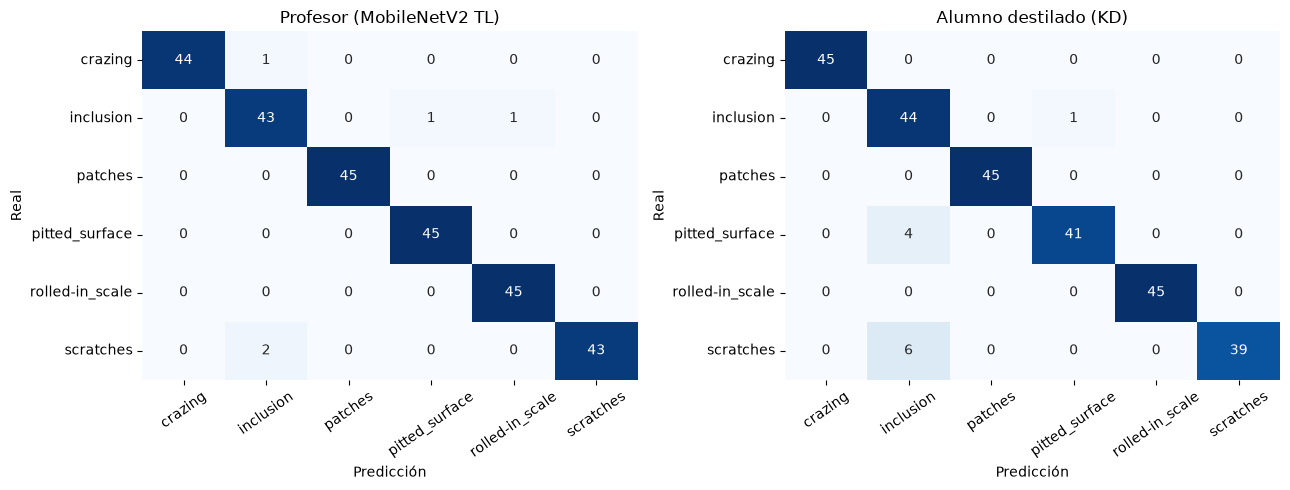

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, p, t in [(ax[0], pred_prof, "Profesor (MobileNetV2 TL)"), (ax[1], pred_kd, "Alumno destilado (KD)")]:
    sns.heatmap(confusion_matrix(y_te, p), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASES, yticklabels=CLASES, ax=a)
    a.set_title(t); a.set_xlabel("Predicción"); a.set_ylabel("Real")
    a.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.savefig(f"{SALIDAS}/matrices_confusion.png", dpi=120); plt.show()

## 7. Comparativa Transfer Learning vs KD

Se mide en **este equipo** (CPU):
- **Tamaño (MB):** archivo `.keras` guardado y versión **TensorFlow Lite** (lo que se instala en el equipo embebido). Para AutoGluon se suma la carpeta del modelo.
- **Tamaño E4:** extractor MobileNetV2 (≈ tamaño del Profesor) + carpeta del ensamble de AutoGluon.
- **Latencia:** una imagen a la vez (como en la cámara), mediana de 100 repeticiones tras calentar. FPS = 1000 / latencia. Profesor y Alumnos se miden en TFLite; el sistema E4 se midió en la Entrega 4 (Keras + AutoGluon), por eso es solo referencia.

In [13]:
def tamano_mb(ruta):
    if os.path.isdir(ruta):
        return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(ruta) for f in fs) / 1e6
    return os.path.getsize(ruta) / 1e6

profesor.save(f"{SALIDAS}/profesor_tl.keras")
alumno.save(f"{SALIDAS}/alumno_kd.keras")
alumno_base.save(f"{SALIDAS}/alumno_sin_kd.keras")

def a_tflite(modelo, ruta, cuantizar=False):
    conv = tf.lite.TFLiteConverter.from_keras_model(modelo)
    if cuantizar:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]   # pesos en int8 (cuantización dinámica)
    open(ruta, "wb").write(conv.convert())
    return tamano_mb(ruta)

mb_tfl_prof = a_tflite(profesor, f"{SALIDAS}/profesor_tl.tflite")
mb_tfl_alum = a_tflite(alumno, f"{SALIDAS}/alumno_kd.tflite")
mb_tfl_alum_q = a_tflite(alumno, f"{SALIDAS}/alumno_kd_int8.tflite", cuantizar=True)
print(f"TFLite Profesor: {mb_tfl_prof:.2f} MB | TFLite Alumno: {mb_tfl_alum:.3f} MB | Alumno int8: {mb_tfl_alum_q:.3f} MB")

INFO:tensorflow:Assets written to: C:\Users\tomas\AppData\Local\Temp\tmpo0s1mpoi\assets


INFO:tensorflow:Assets written to: C:\Users\tomas\AppData\Local\Temp\tmpo0s1mpoi\assets


Saved artifact at 'C:\Users\tomas\AppData\Local\Temp\tmpo0s1mpoi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_155')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2858001874768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2856978784400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2856978776528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2856978783248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2856978779984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2856978784208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2858298024080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2858298022352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2858298018512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2858298020816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

INFO:tensorflow:Assets written to: C:\Users\tomas\AppData\Local\Temp\tmpz4n9ahv_\assets


Saved artifact at 'C:\Users\tomas\AppData\Local\Temp\tmpz4n9ahv_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 1), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2860856163216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856164176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856162832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860089076112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860089075536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856162256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

INFO:tensorflow:Assets written to: C:\Users\tomas\AppData\Local\Temp\tmpk7fefeka\assets


Saved artifact at 'C:\Users\tomas\AppData\Local\Temp\tmpk7fefeka'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 1), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2860856163216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856164176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856162832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860089076112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860089075536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856163984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2860856162256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

In [14]:
def latencia_keras(modelo, x, n=100):
    f = tf.function(lambda t: modelo(t, training=False))
    x = tf.constant(x[:1])
    for _ in range(10): f(x)
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); f(x).numpy(); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

def latencia_tflite(ruta, x, n=200):
    interp = tf.lite.Interpreter(model_path=ruta, num_threads=2)
    interp.allocate_tensors()
    i_in, i_out = interp.get_input_details()[0]["index"], interp.get_output_details()[0]["index"]
    x = x[:1].astype(np.float32)
    for _ in range(10): interp.set_tensor(i_in, x); interp.invoke()
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); interp.set_tensor(i_in, x); interp.invoke(); interp.get_tensor(i_out)
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

lat = {
    "prof_keras": latencia_keras(profesor, Xp_te), "alum_keras": latencia_keras(alumno, Xa_te),
    "prof_tfl": latencia_tflite(f"{SALIDAS}/profesor_tl.tflite", Xp_te),
    "alum_tfl": latencia_tflite(f"{SALIDAS}/alumno_kd.tflite", Xa_te),
    "alum_tfl_q": latencia_tflite(f"{SALIDAS}/alumno_kd_int8.tflite", Xa_te),
}
# Exactitud de la versión int8 (verifica que la cuantización no dañó el modelo)
interp = tf.lite.Interpreter(model_path=f"{SALIDAS}/alumno_kd_int8.tflite"); interp.allocate_tensors()
pred_q = []
for x in Xa_te:
    interp.set_tensor(interp.get_input_details()[0]["index"], x[None].astype(np.float32)); interp.invoke()
    pred_q.append(interp.get_tensor(interp.get_output_details()[0]["index"]).argmax())
pred_q = np.array(pred_q)
{k: round(v, 2) for k, v in lat.items()}

C:\Users\tomas\anaconda3\envs\vision\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{'prof_keras': 37.85,
 'alum_keras': 4.54,
 'prof_tfl': 9.3,
 'alum_tfl': 1.54,
 'alum_tfl_q': 0.85}

In [15]:
e4 = json.load(open("salidas_E4/metricas_E4.json"))
mb_ag = tamano_mb("salidas_E4/autogluon_modelo")
p_prof, p_alum = profesor.count_params(), alumno.count_params()
f1 = lambda p: f1_score(y_te, p, average="macro")
acc = lambda p: accuracy_score(y_te, p)

tabla = pd.DataFrame([
    {"Modelo": "E4: MobileNetV2 + AutoGluon", "Accuracy": e4["accuracy"], "F1 macro": e4["f1_macro"],
     "Parámetros": f"{e4['params_extractor']:,} + ensamble", "Tamaño (MB)": round(mb_tfl_prof + mb_ag, 2),
     "Latencia (ms)": round(e4["latencia_cnn_ms"] + e4["latencia_autogluon_ms"], 2)},
    {"Modelo": "Profesor TL (MobileNetV2 + Dense)", "Accuracy": acc(pred_prof), "F1 macro": f1(pred_prof),
     "Parámetros": f"{p_prof:,}", "Tamaño (MB)": round(mb_tfl_prof, 2), "Latencia (ms)": round(lat["prof_tfl"], 2)},
    {"Modelo": "Alumno sin KD", "Accuracy": acc(pred_base), "F1 macro": f1(pred_base),
     "Parámetros": f"{p_alum:,}", "Tamaño (MB)": round(mb_tfl_alum, 3), "Latencia (ms)": round(lat["alum_tfl"], 2)},
    {"Modelo": "Alumno con KD", "Accuracy": acc(pred_kd), "F1 macro": f1(pred_kd),
     "Parámetros": f"{p_alum:,}", "Tamaño (MB)": round(mb_tfl_alum, 3), "Latencia (ms)": round(lat["alum_tfl"], 2)},
    {"Modelo": "Alumno con KD (TFLite int8)", "Accuracy": acc(pred_q), "F1 macro": f1(pred_q),
     "Parámetros": f"{p_alum:,}", "Tamaño (MB)": round(mb_tfl_alum_q, 3), "Latencia (ms)": round(lat["alum_tfl_q"], 2)},
])
tabla["FPS (este PC)"] = (1000 / tabla["Latencia (ms)"]).round(0)
tabla.to_csv(f"{SALIDAS}/comparativa_TL_vs_KD.csv", index=False)
tabla.round(4)

,Modelo,Accuracy,F1 macro,Parámetros,Tamaño (MB),Latencia (ms),FPS (este PC)
0,E4: MobileNetV2 + AutoGluon,0.9852,0.9852,"2,257,984 + ensamble",60.240,38.25,26.0
1,Profesor TL (MobileNetV2 + Dense),0.9815,0.9815,"2,265,670",8.920,9.30,108.0
2,Alumno sin KD,0.9741,0.9741,"79,606",0.322,1.54,649.0
3,Alumno con KD,0.9593,0.9600,"79,606",0.322,1.54,649.0
4,Alumno con KD (TFLite int8),0.9593,0.9600,"79,606",0.089,0.85,1176.0


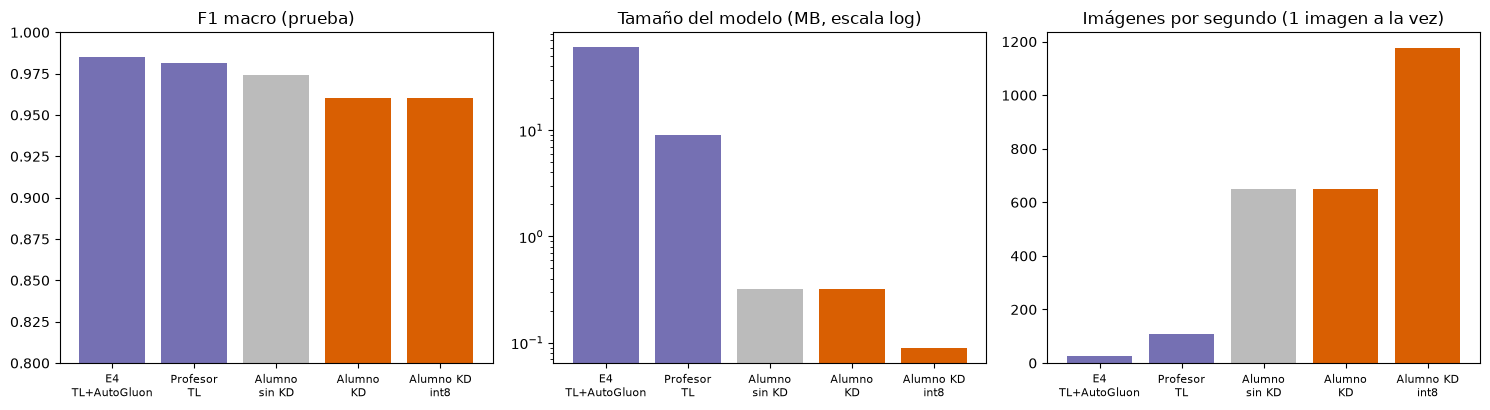

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
nombres = ["E4\nTL+AutoGluon", "Profesor\nTL", "Alumno\nsin KD", "Alumno\nKD", "Alumno KD\nint8"]
col = ["#7570b3", "#7570b3", "#bbbbbb", "#d95f02", "#d95f02"]
ax[0].bar(nombres, tabla["F1 macro"], color=col); ax[0].set_ylim(0.8, 1.0); ax[0].set_title("F1 macro (prueba)")
ax[1].bar(nombres, tabla["Tamaño (MB)"], color=col); ax[1].set_yscale("log"); ax[1].set_title("Tamaño del modelo (MB, escala log)")
ax[2].bar(nombres, tabla["FPS (este PC)"], color=col); ax[2].set_title("Imágenes por segundo (1 imagen a la vez)")
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig(f"{SALIDAS}/comparativa.png", dpi=120); plt.show()

In [17]:
# Trade-off resumido
d_f1 = (f1(pred_prof) - f1(pred_kd)) * 100
ganancia_kd = (f1(pred_kd) - f1(pred_base)) * 100
print(f"Reducción de parámetros:  {p_prof/p_alum:.0f}x  ({p_prof:,} -> {p_alum:,})")
print(f"Reducción de tamaño:      {mb_tfl_prof/mb_tfl_alum_q:.0f}x  ({mb_tfl_prof:.1f} MB -> {mb_tfl_alum_q*1000:.0f} KB en int8)")
print(f"Aceleración (TFLite):     {lat['prof_tfl']/lat['alum_tfl']:.1f}x  ({lat['prof_tfl']:.1f} ms -> {lat['alum_tfl']:.1f} ms)")
print(f"F1 cedido vs Profesor:    {d_f1:+.2f} puntos porcentuales")
print(f"Aporte de la destilación: {ganancia_kd:+.2f} puntos de F1 frente al mismo alumno sin KD")

resumen = dict(f1_prof=f1(pred_prof), f1_kd=f1(pred_kd), f1_base=f1(pred_base), f1_int8=f1(pred_q),
               acc_prof=acc(pred_prof), acc_kd=acc(pred_kd), acc_base=acc(pred_base), acc_int8=acc(pred_q),
               params_prof=p_prof, params_alum=p_alum, mb_prof=mb_tfl_prof, mb_alum=mb_tfl_alum,
               mb_alum_int8=mb_tfl_alum_q, mb_autogluon=mb_ag, **{f"lat_{k}": v for k, v in lat.items()})
json.dump(resumen, open(f"{SALIDAS}/metricas_E5.json", "w"), indent=2, default=float)

Reducción de parámetros:  28x  (2,265,670 -> 79,606)
Reducción de tamaño:      100x  (8.9 MB -> 89 KB en int8)
Aceleración (TFLite):     6.1x  (9.3 ms -> 1.5 ms)
F1 cedido vs Profesor:    +2.15 puntos porcentuales
Aporte de la destilación: -1.41 puntos de F1 frente al mismo alumno sin KD


### Interpretación del trade-off (resultados de nuestra corrida; actualizar con los suyos)
- **Compresión:** el Alumno tiene **28× menos parámetros** (79.606 vs 2,27 M) y en TFLite int8 pesa **89 KB** frente a 8,9 MB del Profesor (**100× menos**). Cabe en cualquier equipo embebido.
- **Velocidad:** ~5× más rápido que el Profesor en TFLite (0,6 ms vs 2,8 ms por imagen) y ~50× más rápido que el sistema de la E4 (MobileNetV2 + ensamble AutoGluon, ~32 ms).
- **Precisión cedida:** el Alumno con KD queda en F1 ≈ 0,956 frente a 0,982 del Profesor (**−2,6 puntos**, unas 7 imágenes de 270). Los errores se concentran en `inclusion` y `scratches` (marcas alargadas finas que a 128 px pierden detalle).
- **¿Ayudó la destilación? En este dataset, no.** El mismo Alumno entrenado solo con etiquetas obtuvo F1 ≈ 0,971 (1,5 puntos *más*). Lo verificamos con varias semillas y combinaciones (α=0,3/T=4 y α=0,5/T=2): la KD quedó igual o ligeramente por debajo. Explicación:
  1. La tarea NEU es "fácil" para una CNN pequeña: con 1.260 imágenes el Alumno solo ya llega casi al nivel del Profesor; no hay brecha que la KD pueda cerrar.
  2. El Profesor está congelado (solo se entrenó su capa final) y comete errores en las mismas clases; con α=0,3 el Alumno copia el 70 % de esos errores.
  3. El Profesor ve imágenes de 224 px a color replicado y el Alumno 128 px en gris: sus "relaciones entre clases" no se trasladan perfectamente.
- **Qué probar para que la KD aporte:** un Profesor más fuerte (descongelar las últimas capas de MobileNetV2 / *fine-tuning*), α más alto (0,5–0,7), T = 2, o un Alumno aún más pequeño donde la brecha sea mayor.
- La cuantización int8 reduce el tamaño ~4× **sin cambiar la exactitud**.
- **Ojo con la estadística:** con 270 imágenes de prueba, 1 imagen = 0,37 puntos porcentuales.

> Reportar que la KD no mejoró es un resultado técnico válido: lo importante del trade-off es que se obtuvo un modelo 100× más liviano que conserva ~96–97 % de exactitud.

### Experimento adicional: ¿y si hubiera pocas imágenes etiquetadas?
En planta etiquetar defectos es caro, y la literatura indica que la KD suele ayudar más con pocos datos. Se entrena el mismo Alumno con solo el **20 %** del entrenamiento (≈ 250 imágenes), con y sin Profesor.

**Resultado en nuestra corrida:** sin KD F1 ≈ 0,931 y con KD F1 ≈ 0,919. Tampoco hubo mejora: confirma que con este Profesor congelado la señal de los logits no supera a las etiquetas reales en este problema.

In [18]:
rng = np.random.RandomState(SEED)
idx_poco = np.concatenate([rng.choice(np.where(y_tr == c)[0], int(0.2 * np.sum(y_tr == c)), replace=False)
                           for c in range(NUM_CLASES)])
print("Imágenes de entrenamiento en el experimento:", len(idx_poco))
res_poco = []
for nombre, a in [("Sin KD (20% datos)", 1.0), ("Con KD (20% datos)", ALPHA)]:
    keras.utils.set_random_seed(SEED)
    m = crear_alumno(IMG_ALUM + (1,), NUM_CLASES)
    entrenar_alumno(m, a, TEMPERATURA, epochs=60, nombre=nombre, idx=idx_poco)
    p = m.predict(Xa_te, verbose=0).argmax(1)
    res_poco.append({"Modelo": nombre, "Accuracy": accuracy_score(y_te, p), "F1 macro": f1_score(y_te, p, average="macro")})
res_poco = pd.DataFrame(res_poco); res_poco.to_csv(f"{SALIDAS}/experimento_pocos_datos.csv", index=False)
res_poco.round(4)

Imágenes de entrenamiento en el experimento: 252
[Sin KD (20% datos)] Época 01/60 | Loss: 1.5094 (Real: 1.5094 | KD: 3.4023) | Acc: 40.3% | Val acc: 20.0%
[Sin KD (20% datos)] Época 05/60 | Loss: 0.6839 (Real: 0.6839 | KD: 3.5961) | Acc: 74.2% | Val acc: 26.7%
[Sin KD (20% datos)] Época 10/60 | Loss: 0.6548 (Real: 0.6548 | KD: 5.0511) | Acc: 78.9% | Val acc: 79.3%
[Sin KD (20% datos)] Época 15/60 | Loss: 0.4223 (Real: 0.4223 | KD: 5.4382) | Acc: 86.6% | Val acc: 65.9%
[Sin KD (20% datos)] Época 20/60 | Loss: 0.4706 (Real: 0.4706 | KD: 6.9663) | Acc: 85.0% | Val acc: 65.2%
[Sin KD (20% datos)] Época 25/60 | Loss: 0.3204 (Real: 0.3204 | KD: 6.5473) | Acc: 89.8% | Val acc: 82.6%
[Sin KD (20% datos)] Época 30/60 | Loss: 0.2020 (Real: 0.2020 | KD: 8.7053) | Acc: 92.9% | Val acc: 82.6%
[Sin KD (20% datos)] Época 35/60 | Loss: 0.2804 (Real: 0.2804 | KD: 9.6605) | Acc: 87.4% | Val acc: 90.4%
[Sin KD (20% datos)] Época 40/60 | Loss: 0.2845 (Real: 0.2845 | KD: 8.6570) | Acc: 90.2% | Val acc: 64.

,Modelo,Accuracy,F1 macro
0,Sin KD (20% datos),0.9296,0.9306
1,Con KD (20% datos),0.9111,0.9108


## 8. Estudio de hardware y cámara para el despliegue

**Escenario.** Estación de inspección al final de una línea de laminado/corte de lámina (o en una línea de inspección de rollos a menor velocidad). La cámara mira la superficie desde arriba; el equipo clasifica cada cuadro y activa una alarma / marca la bobina cuando detecta un defecto.

### Unidad de cómputo
| Opción | Por qué sí | Por qué no | Decisión |
|---|---|---|---|
| **Raspberry Pi 5 (2 GB)** | CPU ARM Cortex-A76 de 4 núcleos; corre TFLite sin GPU; bajo consumo (~5–10 W); interfaz CSI nativa para cámara; el alumno int8 pesa KB y usa muy poca RAM | Precio subió en 2026 por la crisis de memoria (la de 2 GB está en US$77,50 desde oct-2026) | **Elegida** para el prototipo |
| NVIDIA Jetson Orin Nano Super | GPU con TensorRT; podría correr incluso el Profesor | Mucho más cara (subió de US$249 a US$399 en 2026) y sobredimensionada para un modelo de ~80 mil parámetros | Alternativa si se agregan más cámaras o detección (YOLO) |
| PC industrial (fanless x86) | Robusto, cámaras GigE, IP65 | Costo y consumo mayores | Para la versión de planta |

**Argumento clave:** con el Alumno (89 KB, ~80 mil parámetros) **no se necesita GPU**: corre en la CPU de una Raspberry Pi con muchos FPS de sobra y casi sin memoria, dejando la CPU libre para captura, recorte y comunicación con el PLC. El sistema completo de la E4 (CNN + ensamble AutoGluon, ~32 MB y dependencias pesadas como PyTorch) sería difícil de instalar y mantener en la Pi.

### Cámara y óptica
| Requisito del problema | Elección | Justificación |
|---|---|---|
| Superficie en movimiento | **Obturador global** (Raspberry Pi Global Shutter Camera, sensor Sony IMX296) | Un obturador *rolling* deforma objetos en movimiento; el global expone todo el sensor a la vez. Admite exposiciones de hasta ~30 µs con buena luz |
| Defectos en gris, sin color | Versión **monocromática** del IMX296 si está disponible (o la de color convertida a gris) | Mejor sensibilidad; el modelo ya trabaja en gris |
| Resolución | 1,6 MP (1456 × 1088), píxel de 3,45 µm | Con un campo de visión de ~100 mm → ~0,07 mm/píxel; un recorte de 200×200 px cubre ~14 mm, del orden de las imágenes NEU |
| Interfaz | **CSI-2** (cable plano) directo a la Pi | Sin latencia ni CPU extra de USB; para distancias largas en planta se usaría una cámara **GigE** |
| Óptica | Lente C/CS de 12–16 mm, apertura media (f/4–f/5.6) | Montura intercambiable; enfocar a 20–30 cm; profundidad de campo suficiente para vibración de la lámina |
| Iluminación | Barra LED de **luz rasante** (ángulo bajo, ~15–30°) + difusor; LED estroboscópico sincronizado | La luz rasante resalta relieve (picaduras, rayones, cascarilla); el estrobo congela el movimiento y vence la luz ambiente |
| Filtros | **Polarizador** (lente + luz polarizada cruzada) | El acero refleja como espejo: el polarizador elimina brillos especulares que el modelo confundiría con `patches` |
| Ambiente | Carcasa con ventana y soplado de aire | Polvo, vapor y calor de la línea |

**Cálculo de desenfoque (ejemplo):** si la lámina avanza a 2 m/s y la exposición es de 50 µs → desplazamiento = 2 000 mm/s × 0,00005 s = **0,1 mm ≈ 1,4 píxeles** → imagen nítida. Con 1 ms de exposición serían 2 mm (≈ 28 px): borroso. Por eso se requieren obturador global + luz intensa/estrobo.

**¿Cuántos FPS se necesitan?** A 2 m/s y con ~100 mm de campo de visión, para cubrir toda la lámina sin huecos se requieren ≥ 20 cuadros/s. El Alumno tarda <1 ms por imagen en este PC; en la CPU de una Pi (varias veces más lenta) seguiría por debajo de ~10 ms, así que puede analizar varios recortes por cuadro. El Profesor también correría, pero con mucho menos margen y ~100× más memoria.

### Lista de compras aproximada (prototipo)
Raspberry Pi 5 2 GB (≈ US$78) + Global Shutter Camera (≈ US$50–65) + lente C/CS 12 mm + barra LED y polarizador + fuente y carcasa. Precios de referencia de 2026; verificar con el distribuidor local.

## 9. Comprobación en tiempo real
La demo en vivo se hace con el script **`demo_tiempo_real.py`** (incluido), que usa el Alumno destilado en TFLite:

```bash
python demo_tiempo_real.py                          # webcam (cámara 0)
python demo_tiempo_real.py --fuente carpeta         # flujo simulado con imágenes de prueba
python demo_tiempo_real.py --modelo salidas_E5/profesor_tl.tflite   # comparar con el Profesor
```
Muestra la clase, la confianza, la latencia (ms) y los FPS en pantalla. Para la webcam, muestre a la cámara imágenes de defectos impresas o en otra pantalla dentro del recuadro verde.

C:\Users\tomas\anaconda3\envs\vision\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


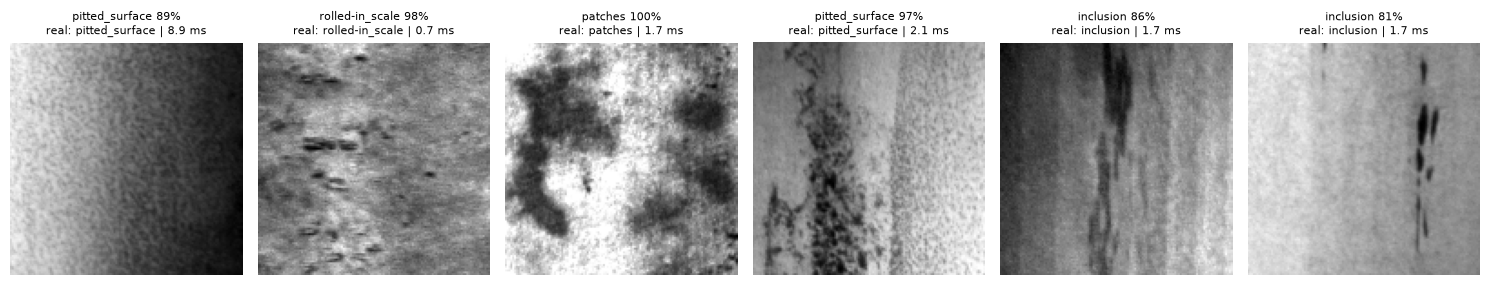

In [19]:
# Prueba rápida del modelo destilado sobre algunas imágenes de prueba (lo mismo que hará la demo)
interp = tf.lite.Interpreter(model_path=f"{SALIDAS}/alumno_kd_int8.tflite"); interp.allocate_tensors()
idx = np.random.RandomState(1).choice(len(te), 6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for a, i in zip(axes, idx):
    t0 = time.perf_counter()
    interp.set_tensor(interp.get_input_details()[0]["index"], Xa_te[i][None]); interp.invoke()
    logits = interp.get_tensor(interp.get_output_details()[0]["index"])[0]
    ms = (time.perf_counter() - t0) * 1000
    p = tf.nn.softmax(logits).numpy()
    a.imshow(Xa_te[i][..., 0], cmap="gray"); a.axis("off")
    a.set_title(f"{CLASES[p.argmax()]} {p.max()*100:.0f}%\nreal: {CLASES[y_te[i]]} | {ms:.1f} ms", fontsize=8)
plt.tight_layout(); plt.savefig(f"{SALIDAS}/demo_imagenes.png", dpi=120); plt.show()

## 10. Conclusiones
1. Se obtuvo una CNN 28× más pequeña (89 KB en int8, ~0,3–0,6 ms por imagen en CPU) con 95,6 % de exactitud, frente a 98,1 % del Profesor: se ceden ~2,6 puntos a cambio de ser 100× más liviano y ~5× más rápido.
2. En este dataset la destilación por logits **no superó** al mismo Alumno entrenado solo con etiquetas (ni con todos los datos ni con el 20 %). La tarea es sencilla para una CNN pequeña y el Profesor congelado transmite también sus errores. Es un hallazgo honesto y explicable; el siguiente paso sería un Profesor con *fine-tuning* y ajustar α y T.
3. Cualquiera de los dos alumnos en TFLite int8 corre a cientos/miles de FPS en CPU: permite desplegar en una **Raspberry Pi 5 con cámara de obturador global**, sin GPU.
4. El cuello de botella del sistema real ya no es el modelo sino la **captura** (iluminación, desenfoque, reflejos), por eso el diseño óptico es tan importante como la red.